In [1]:
from ultralytics import YOLO

In [2]:
model = YOLO("yolo11n.pt")

In [3]:
model

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_

In [4]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 2050


In [5]:
import sys
print(sys.executable)

D:\PCB Defect Detection\.venv\Scripts\python.exe


In [6]:
results = model.train(
    data=r"D:\pcb-defect-dataset-working\data.yaml",
    epochs=50,
    imgsz=600,
    batch=8,
    device=0,
    workers=0,
    project=r"D:\PCB Defect Detection\results",
    name="pcb_yolo_baseline_w0"
)

New https://pypi.org/project/ultralytics/8.4.173 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.163  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\pcb-defect-dataset-working\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=600, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode

In [7]:
from ultralytics import YOLO

model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

test_results = model.val(
    data=r"D:\pcb-defect-dataset-working\data.yaml",
    split="test",
    imgsz=600,
    batch=8,
    device=0,
    workers=0
)

WARNING imgsz=[600] must be multiple of max stride 32, updating to [608]
Ultralytics 8.4.163  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
YOLO11n summary (fused): 100 layers, 2,583,322 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.30.1 ms, read: 158.316.7 MB/s, size: 138.3 KB)
val: Scanning D:\pcb-defect-dataset-working\test\labels... 829 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 829/829 1.1Kit/s 0.7s0.0ss
val: New cache created: D:\pcb-defect-dataset-working\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 104/104 4.4it/s 23.5s0.2s
                   all        829       1662       0.98      0.983      0.989      0.559
            mouse_bite        131        262      0.981      0.991      0.991      0.548
                  spur        138        279      0.979      0.961      0.986      0.549
          missing_hole        145        283      0.9

In [8]:
from ultralytics import YOLO

model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

results = model.predict(
    source=r"D:\pcb-defect-dataset-working\test\images",
    imgsz=600,
    conf=0.25,
    device=0,
    workers=0,
    save=True,
    project=r"D:\PCB Defect Detection\results",
    name="test_predictions"
)


WARNING imgsz=[600] must be multiple of max stride 32, updating to [608]
image 1/829 D:\pcb-defect-dataset-working\test\images\l_light_01_missing_hole_04_2_600.jpg: 608x608 2 missing_holes, 124.3ms
image 2/829 D:\pcb-defect-dataset-working\test\images\l_light_01_missing_hole_07_2_600.jpg: 608x608 2 missing_holes, 60.0ms
image 3/829 D:\pcb-defect-dataset-working\test\images\l_light_01_missing_hole_08_1_600.jpg: 608x608 1 missing_hole, 54.4ms
image 4/829 D:\pcb-defect-dataset-working\test\images\l_light_01_missing_hole_10_2_600.jpg: 608x608 2 missing_holes, 55.8ms
image 5/829 D:\pcb-defect-dataset-working\test\images\l_light_01_missing_hole_14_4_600.jpg: 608x608 1 missing_hole, 55.8ms
image 6/829 D:\pcb-defect-dataset-working\test\images\l_light_01_missing_hole_18_1_600.jpg: 608x608 1 missing_hole, 30.4ms
image 7/829 D:\pcb-defect-dataset-working\test\images\l_light_01_missing_hole_18_3_600.jpg: 608x608 2 missing_holes, 21.4ms
image 8/829 D:\pcb-defect-dataset-working\test\images\l_ligh

In [10]:
from ultralytics import YOLO

model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

results = model.predict(
    source=r"D:\DeepPCB_test",
    imgsz=600,
    conf=0.25,
    device=0,
    save=True,
    project=r"D:\PCB Defect Detection\results",
    name="deepPCB_predictions"
)


WARNING imgsz=[600] must be multiple of max stride 32, updating to [608]
image 1/100 D:\DeepPCB_test\00041000_test.jpg: 608x608 (no detections), 100.4ms
image 2/100 D:\DeepPCB_test\00041001_test.jpg: 608x608 (no detections), 31.3ms
image 3/100 D:\DeepPCB_test\00041002_test.jpg: 608x608 (no detections), 30.2ms
image 4/100 D:\DeepPCB_test\00041003_test.jpg: 608x608 (no detections), 20.6ms
image 5/100 D:\DeepPCB_test\00041004_test.jpg: 608x608 (no detections), 23.7ms
image 6/100 D:\DeepPCB_test\00041005_test.jpg: 608x608 (no detections), 25.3ms
image 7/100 D:\DeepPCB_test\00041006_test.jpg: 608x608 (no detections), 30.0ms
image 8/100 D:\DeepPCB_test\00041007_test.jpg: 608x608 (no detections), 29.8ms
image 9/100 D:\DeepPCB_test\00041008_test.jpg: 608x608 (no detections), 36.1ms
image 10/100 D:\DeepPCB_test\00041009_test.jpg: 608x608 (no detections), 27.2ms
image 11/100 D:\DeepPCB_test\00041010_test.jpg: 608x608 (no detections), 23.3ms
image 12/100 D:\DeepPCB_test\00041011_test.jpg: 608x60

In [11]:
from ultralytics import YOLO

model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

results = model.predict(
    source=r"D:\DeepPCB_test",
    imgsz=600,
    conf=0.01,
    device=0,
    save=True,
    project=r"D:\PCB Defect Detection\results",
    name="deepPCB_predictions_lowconf"
)


WARNING imgsz=[600] must be multiple of max stride 32, updating to [608]
image 1/100 D:\DeepPCB_test\00041000_test.jpg: 608x608 (no detections), 32.7ms
image 2/100 D:\DeepPCB_test\00041001_test.jpg: 608x608 (no detections), 30.6ms
image 3/100 D:\DeepPCB_test\00041002_test.jpg: 608x608 (no detections), 20.3ms
image 4/100 D:\DeepPCB_test\00041003_test.jpg: 608x608 (no detections), 23.1ms
image 5/100 D:\DeepPCB_test\00041004_test.jpg: 608x608 (no detections), 26.4ms
image 6/100 D:\DeepPCB_test\00041005_test.jpg: 608x608 (no detections), 21.2ms
image 7/100 D:\DeepPCB_test\00041006_test.jpg: 608x608 (no detections), 25.8ms
image 8/100 D:\DeepPCB_test\00041007_test.jpg: 608x608 (no detections), 19.5ms
image 9/100 D:\DeepPCB_test\00041008_test.jpg: 608x608 (no detections), 18.5ms
image 10/100 D:\DeepPCB_test\00041009_test.jpg: 608x608 (no detections), 32.4ms
image 11/100 D:\DeepPCB_test\00041010_test.jpg: 608x608 (no detections), 23.7ms
image 12/100 D:\DeepPCB_test\00041011_test.jpg: 608x608

In [12]:
for i, result in enumerate(results[:10]):
    print(f"Image {i+1}: {len(result.boxes)} detections")

Image 1: 0 detections
Image 2: 0 detections
Image 3: 0 detections
Image 4: 0 detections
Image 5: 0 detections
Image 6: 0 detections
Image 7: 0 detections
Image 8: 0 detections
Image 9: 0 detections
Image 10: 0 detections


In [1]:

import sys
import torch
import ultralytics

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Ultralytics:", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python: D:\PCB Defect Detection\.venv\Scripts\python.exe
PyTorch: 2.11.0+cu128
CUDA available: True
Ultralytics: 8.4.163
GPU: NVIDIA GeForce RTX 2050


In [2]:

from pathlib import Path

model_path = Path(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

print("Model exists:", model_path.exists())
print("Model path:", model_path)


Model exists: True
Model path: D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt


In [4]:

from ultralytics import YOLO
from IPython.display import display

model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

results = model.predict(
    source=r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone.jpeg",
    imgsz=608,
    conf=0.25,
    device=0,
    save=True,
    project=r"D:\PCB Defect Detection\results",
    name="college_pcb_phone"
)

display(results[0].plot()[:, :, ::-1])



image 1/1 D:\PCB Defect Detection\pcb_test_images\college_pcb_phone.jpeg: 608x480 1 spur, 5 missing_holes, 88.3ms
Speed: 104.2ms preprocess, 88.3ms inference, 34.4ms postprocess per image at shape (1, 3, 608, 480)
Results saved to D:\PCB Defect Detection\results\college_pcb_phone


array([[[150, 126,  92],
        [154, 130,  96],
        [155, 131,  97],
        ...,
        [ 96, 104, 107],
        [ 92, 100, 103],
        [100, 108, 111]],

       [[152, 128,  94],
        [153, 129,  95],
        [154, 130,  96],
        ...,
        [ 91,  99, 102],
        [ 84,  92,  95],
        [ 90,  98, 101]],

       [[155, 131,  97],
        [153, 129,  95],
        [151, 127,  93],
        ...,
        [109, 117, 120],
        [ 98, 106, 109],
        [101, 109, 112]],

       ...,

       [[ 56,  36,  25],
        [ 58,  38,  27],
        [ 60,  40,  29],
        ...,
        [180, 111, 168],
        [182, 113, 170],
        [183, 114, 171]],

       [[ 57,  37,  28],
        [ 58,  38,  29],
        [ 61,  41,  32],
        ...,
        [182, 113, 170],
        [184, 115, 172],
        [185, 116, 173]],

       [[ 58,  38,  29],
        [ 60,  40,  31],
        [ 63,  43,  34],
        ...,
        [183, 114, 171],
        [185, 116, 173],
        [185, 116, 173]]

Image dimensions: (1280, 960, 3)
Largest contour area: 528856.0


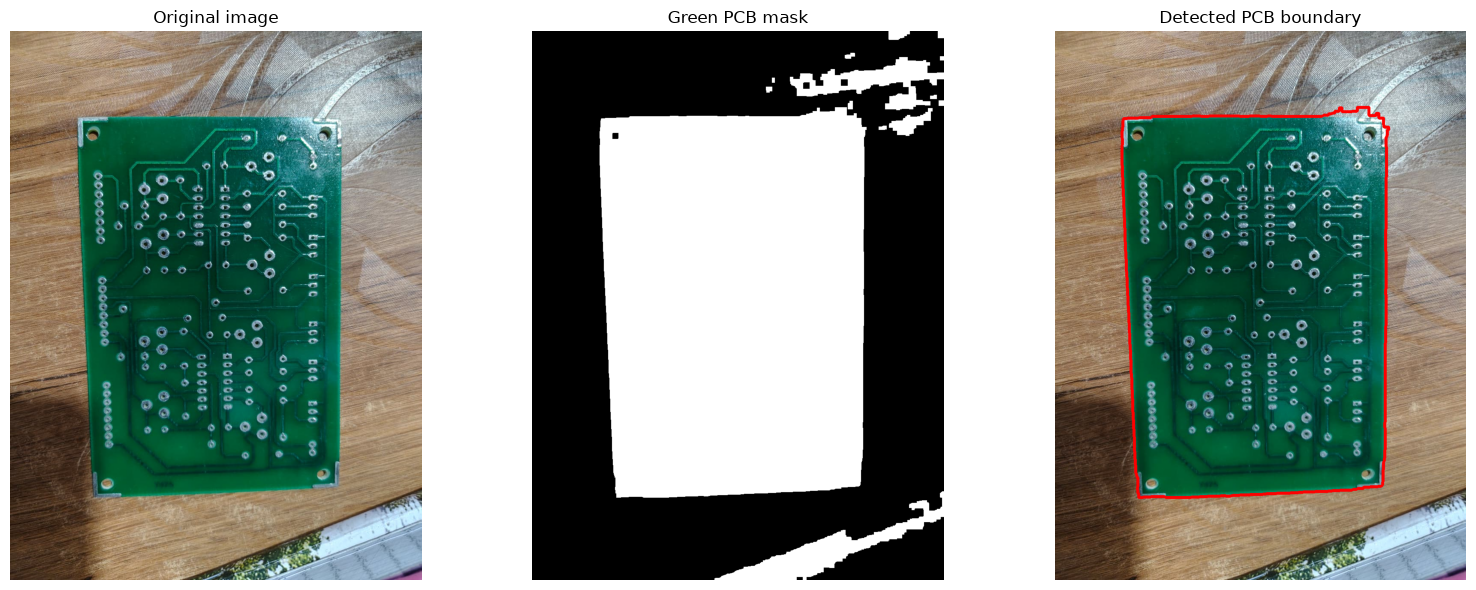

In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load the phone photograph
image_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone.jpeg"
)

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(
        f"Image not found: {image_path}\n"
        "Check that the file exists at this location."
    )

print("Image dimensions:", image.shape)

# 2. Convert the image to HSV colour space
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# 3. Create a mask for green PCB regions
lower_green = np.array([25, 30, 20])
upper_green = np.array([100, 255, 255])

mask = cv2.inRange(hsv, lower_green, upper_green)

# 4. Clean small gaps and noise in the mask
kernel = np.ones((7, 7), np.uint8)

mask = cv2.morphologyEx(
    mask, cv2.MORPH_CLOSE, kernel, iterations=2
)
mask = cv2.morphologyEx(
    mask, cv2.MORPH_OPEN, kernel, iterations=1
)

# 5. Find external contours
contours, _ = cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

if not contours:
    raise RuntimeError(
        "No PCB contour found. We may need to adjust the colour thresholds."
    )

# 6. Select the largest contour as the PCB candidate
pcb_contour = max(contours, key=cv2.contourArea)

area = cv2.contourArea(pcb_contour)
print("Largest contour area:", area)

# 7. Draw the detected boundary
outlined = image.copy()
cv2.drawContours(
    outlined, [pcb_contour], -1, (0, 0, 255), 6
)

# 8. Display the results
plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Green PCB mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(outlined, cv2.COLOR_BGR2RGB))
plt.title("Detected PCB boundary")
plt.axis("off")

plt.tight_layout()
plt.show()


Detected polygon corners: 4


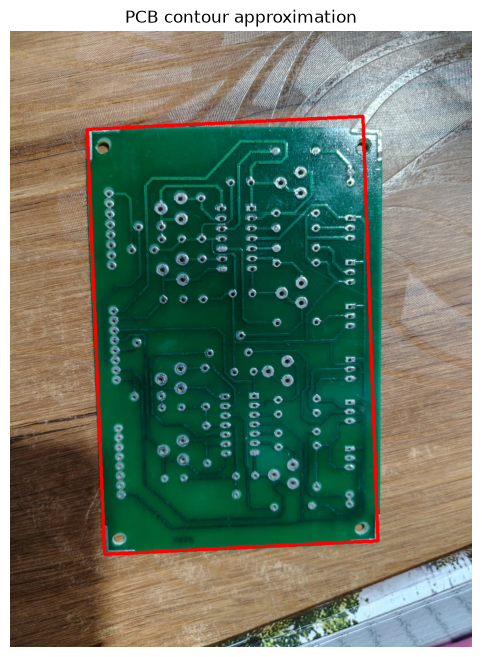

In [7]:

# Approximate the four corners of the PCB
perimeter = cv2.arcLength(pcb_contour, True)

approx = cv2.approxPolyDP(
    pcb_contour,
    0.02 * perimeter,
    True
)

print("Detected polygon corners:", len(approx))

# Display the contour approximation
corner_view = image.copy()
cv2.polylines(
    corner_view,
    [approx],
    True,
    (0, 0, 255),
    5
)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(corner_view, cv2.COLOR_BGR2RGB))
plt.title("PCB contour approximation")
plt.axis("off")
plt.show()


Rectified PCB dimensions: (883, 573, 3)


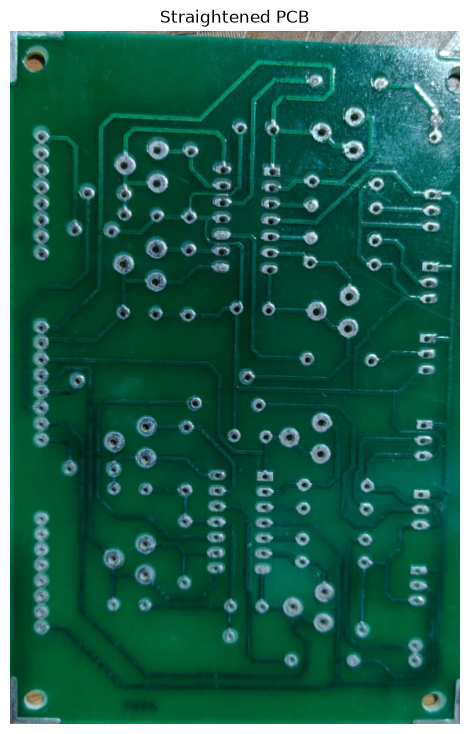

In [8]:

# Extract the four corner points
points = approx.reshape(4, 2).astype(np.float32)

# Order corners: top-left, top-right, bottom-right, bottom-left
ordered = np.zeros((4, 2), dtype=np.float32)

sums = points.sum(axis=1)
diffs = np.diff(points, axis=1).flatten()

ordered[0] = points[np.argmin(sums)]   # Top-left
ordered[2] = points[np.argmax(sums)]   # Bottom-right
ordered[1] = points[np.argmin(diffs)]  # Top-right
ordered[3] = points[np.argmax(diffs)]  # Bottom-left

# Calculate the output dimensions
top_width = np.linalg.norm(ordered[1] - ordered[0])
bottom_width = np.linalg.norm(ordered[2] - ordered[3])
left_height = np.linalg.norm(ordered[3] - ordered[0])
right_height = np.linalg.norm(ordered[2] - ordered[1])

output_width = int(max(top_width, bottom_width))
output_height = int(max(left_height, right_height))

# Map the four corners to a rectangle
destination = np.array([
    [0, 0],
    [output_width - 1, 0],
    [output_width - 1, output_height - 1],
    [0, output_height - 1]
], dtype=np.float32)

matrix = cv2.getPerspectiveTransform(ordered, destination)

pcb_crop = cv2.warpPerspective(
    image,
    matrix,
    (output_width, output_height)
)

print("Rectified PCB dimensions:", pcb_crop.shape)

# Display the result
plt.figure(figsize=(7, 9))
plt.imshow(cv2.cvtColor(pcb_crop, cv2.COLOR_BGR2RGB))
plt.title("Straightened PCB")
plt.axis("off")
plt.show()


Image dimensions: (1280, 960, 3)


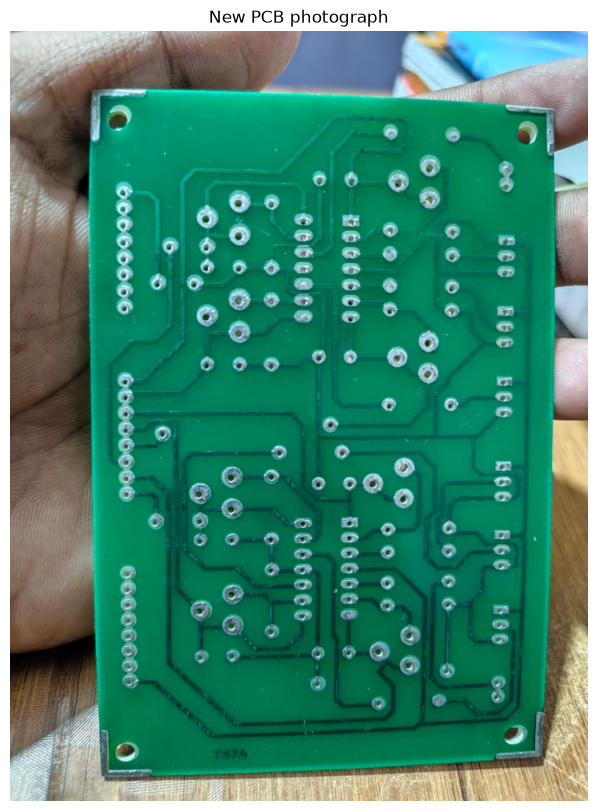

In [12]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

image_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2.jpg"
)
image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

print("Image dimensions:", image.shape)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("New PCB photograph")
plt.axis("off")
plt.show()



image 1/1 D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2.jpg: 608x480 1 mouse_bite, 1 missing_hole, 87.7ms
Speed: 9.1ms preprocess, 87.7ms inference, 4.7ms postprocess per image at shape (1, 3, 608, 480)
Results saved to D:\PCB Defect Detection\results\phone_pcb_test


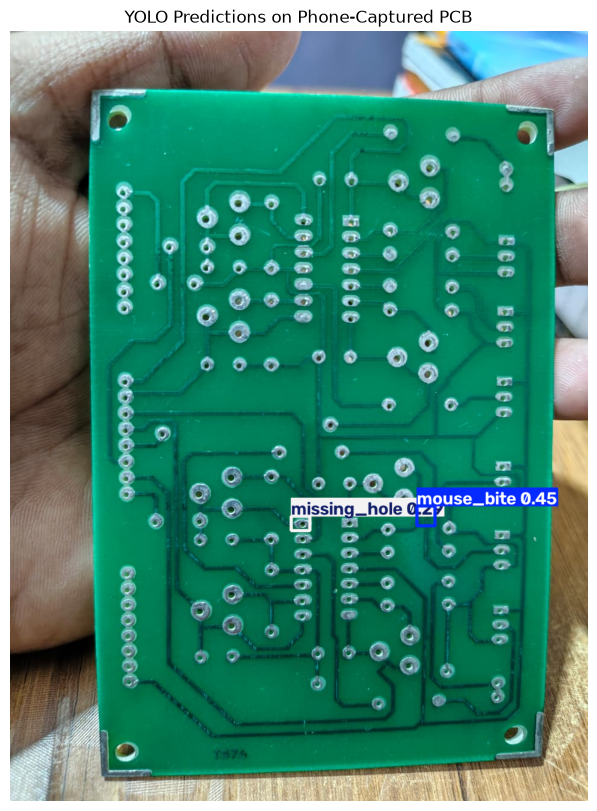

Detections: 2
Saved results to: D:\PCB Defect Detection\results\phone_pcb_test


In [14]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Load our trained model
model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

# Use the actual image path from your Windows computer
image_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2.jpg"
)

# Check that the image exists
if not image_path.exists():
    raise FileNotFoundError(
        f"Image not found: {image_path}\n"
        "Replace image_path with the actual location of your photo."
    )

# Run detection
results = model.predict(
    source=str(image_path),
    imgsz=608,
    conf=0.25,
    device=0,
    save=True,
    project=r"D:\PCB Defect Detection\results",
    name="phone_pcb_test"
)

# Display predictions
result = results[0]
annotated_image = result.plot()

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.title("YOLO Predictions on Phone-Captured PCB")
plt.axis("off")
plt.show()

print("Detections:", len(result.boxes))
print("Saved results to:", result.save_dir)


Rectified PCB dimensions: (938, 939, 3)
Tiles: 3 columns x 4 rows
Raw tile detections: 3


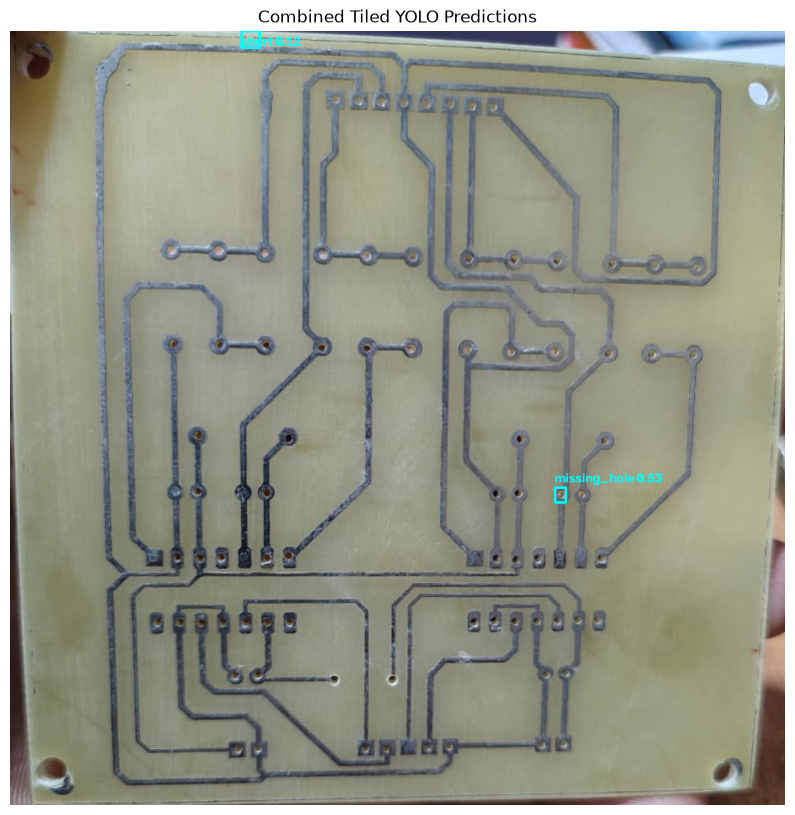

Final detections after duplicate removal: 2
Saved combined image: D:\PCB Defect Detection\results\phone_pcb_tiled_result.jpg
missing_hole: 0.533
short: 0.115


In [16]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from pathlib import Path

# --------------------------------------------------
# 1. Load the photograph and trained model
# --------------------------------------------------
image_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_2.jpg"
)
image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

# --------------------------------------------------
# 2. Find the green PCB and rectify its perspective
# --------------------------------------------------
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

green_mask = cv2.inRange(
    hsv,
    np.array([30, 25, 20]),
    np.array([100, 255, 255])
)

kernel = np.ones((7, 7), np.uint8)
green_mask = cv2.morphologyEx(
    green_mask, cv2.MORPH_CLOSE, kernel, iterations=2
)
green_mask = cv2.morphologyEx(
    green_mask, cv2.MORPH_OPEN, kernel
)

contours, _ = cv2.findContours(
    green_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

if not contours:
    raise RuntimeError("PCB boundary not detected. Check the lighting or mask.")

contour = max(contours, key=cv2.contourArea)
perimeter = cv2.arcLength(contour, True)
approx = cv2.approxPolyDP(contour, 0.02 * perimeter, True)

if len(approx) == 4:
    corners = approx.reshape(4, 2).astype(np.float32)
else:
    # Fallback if the PCB contour isn't a clean quadrilateral
    corners = cv2.boxPoints(
        cv2.minAreaRect(contour)
    ).astype(np.float32)

def order_corners(points):
    ordered = np.zeros((4, 2), dtype=np.float32)
    sums = points.sum(axis=1)
    diffs = np.diff(points, axis=1).ravel()

    ordered[0] = points[np.argmin(sums)]   # top-left
    ordered[2] = points[np.argmax(sums)]   # bottom-right
    ordered[1] = points[np.argmin(diffs)]  # top-right
    ordered[3] = points[np.argmax(diffs)]  # bottom-left

    return ordered

corners = order_corners(corners)
tl, tr, br, bl = corners

width = int(max(np.linalg.norm(br - bl), np.linalg.norm(tr - tl)))
height = int(max(np.linalg.norm(tr - br), np.linalg.norm(tl - bl)))

destination = np.array([
    [0, 0],
    [width - 1, 0],
    [width - 1, height - 1],
    [0, height - 1]
], dtype=np.float32)

transform = cv2.getPerspectiveTransform(corners, destination)
pcb = cv2.warpPerspective(image, transform, (width, height))

print("Rectified PCB dimensions:", pcb.shape)

# --------------------------------------------------
# 3. Generate overlapping tiles
# --------------------------------------------------
tile_w = min(480, width)
tile_h = min(360, height)

def tile_starts(length, tile_size, overlap=0.20):
    if length <= tile_size:
        return [0]

    stride = max(1, int(tile_size * (1 - overlap)))
    starts = list(range(0, length - tile_size + 1, stride))

    # Ensure the final edge is covered
    last_start = length - tile_size
    if starts[-1] != last_start:
        starts.append(last_start)

    return sorted(set(starts))

x_starts = tile_starts(width, tile_w)
y_starts = tile_starts(height, tile_h)

print(f"Tiles: {len(x_starts)} columns x {len(y_starts)} rows")

# --------------------------------------------------
# 4. Run YOLO on every tile
# --------------------------------------------------
all_boxes = []
all_scores = []
all_classes = []

for y in y_starts:
    for x in x_starts:
        tile = pcb[y:y + tile_h, x:x + tile_w]

        results = model.predict(
            source=tile,
            imgsz=608,
            conf=0.10,
            device=0,
            verbose=False
        )

        for box in results[0].boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

            # Convert tile coordinates to full-PCB coordinates
            all_boxes.append([
                x1 + x, y1 + y, x2 + x, y2 + y
            ])
            all_scores.append(float(box.conf[0]))
            all_classes.append(int(box.cls[0]))

print("Raw tile detections:", len(all_boxes))

# --------------------------------------------------
# 5. Merge duplicate detections from overlapping tiles
# --------------------------------------------------
final_indices = []

for class_id in sorted(set(all_classes)):
    indices = [
        i for i, c in enumerate(all_classes)
        if c == class_id
    ]

    if not indices:
        continue

    boxes_for_class = [
        all_boxes[i] for i in indices
    ]
    scores_for_class = [
        all_scores[i] for i in indices
    ]

    # OpenCV NMS expects [x, y, width, height]
    nms_boxes = [
        [
            int(b[0]), int(b[1]),
            int(b[2] - b[0]), int(b[3] - b[1])
        ]
        for b in boxes_for_class
    ]

    kept = cv2.dnn.NMSBoxes(
        nms_boxes,
        scores_for_class,
        score_threshold=0.10,
        nms_threshold=0.45
    )

    if len(kept) > 0:
        final_indices.extend(
            indices[int(k)] for k in np.array(kept).flatten()
        )

# --------------------------------------------------
# 6. Draw all retained detections on one PCB image
# --------------------------------------------------
output = pcb.copy()

for i in final_indices:
    x1, y1, x2, y2 = map(
        int, all_boxes[i]
    )

    class_name = model.names[all_classes[i]]
    confidence = all_scores[i]

    cv2.rectangle(
        output, (x1, y1), (x2, y2), (255, 255, 0), 2
    )

    label = f"{class_name} {confidence:.2f}"
    cv2.putText(
        output,
        label,
        (x1, max(18, y1 - 6)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 255, 0),
        2
    )

save_path = Path(
    r"D:\PCB Defect Detection\results\phone_pcb_tiled_result.jpg"
)
save_path.parent.mkdir(parents=True, exist_ok=True)
cv2.imwrite(str(save_path), output)

plt.figure(figsize=(10, 12))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Combined Tiled YOLO Predictions")
plt.axis("off")
plt.show()

print("Final detections after duplicate removal:", len(final_indices))
print("Saved combined image:", save_path)

for i in final_indices:
    print(
        f"{model.names[all_classes[i]]}: "
        f"{all_scores[i]:.3f}"
    )


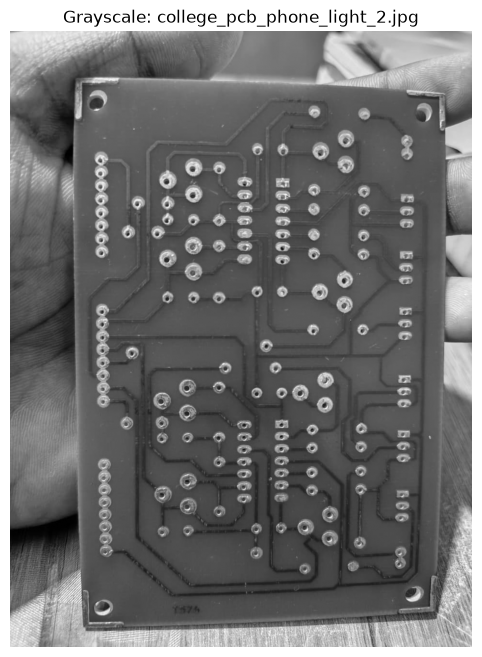

Saved: D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2_gray.jpg


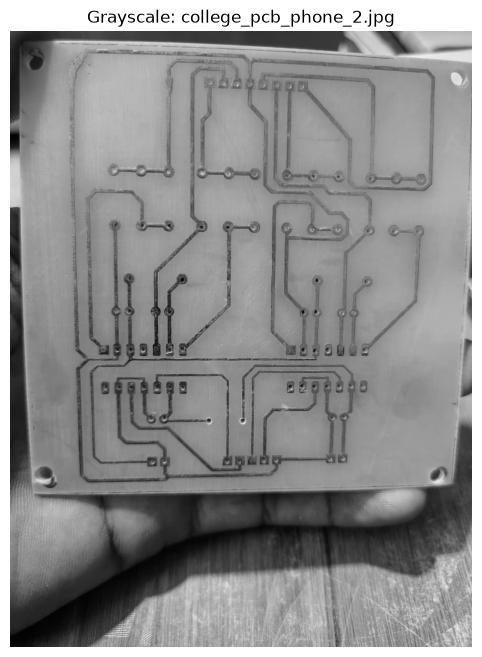

Saved: D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_2_gray.jpg


In [17]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

image_paths = [
    Path(r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2.jpg"),
    Path(r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_2.jpg")
]

for image_path in image_paths:
    image = cv2.imread(str(image_path))

    if image is None:
        print(f"Could not load: {image_path}")
        continue

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    gray_path = image_path.with_name(
        image_path.stem + "_gray.jpg"
    )

    cv2.imwrite(str(gray_path), gray)

    plt.figure(figsize=(7, 8))
    plt.imshow(gray, cmap="gray")
    plt.title(f"Grayscale: {image_path.name}")
    plt.axis("off")
    plt.show()

    print(f"Saved: {gray_path}")



Processing: college_pcb_phone_light_2_gray.jpg
Raw tile detections: 0


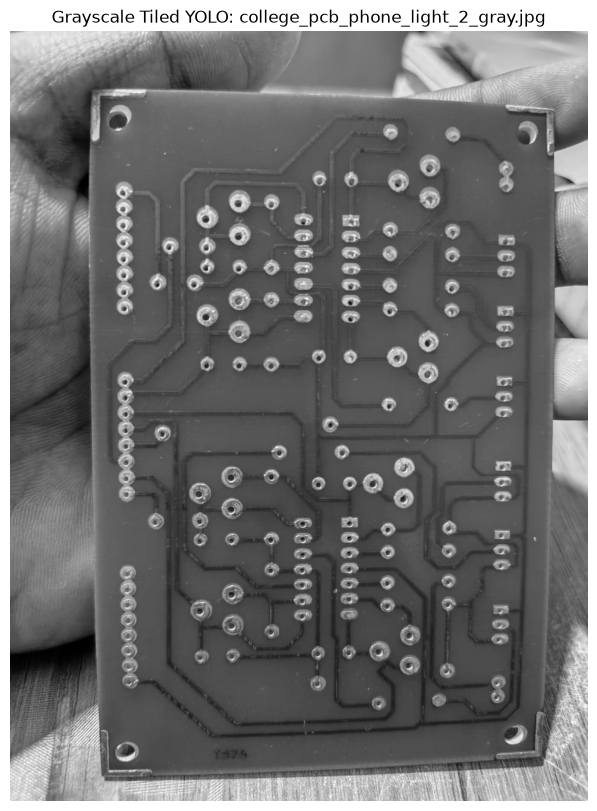

Final detections after NMS: 0
Saved result: D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2_gray_tiled_predictions.jpg

Processing: college_pcb_phone_2_gray.jpg
Raw tile detections: 0


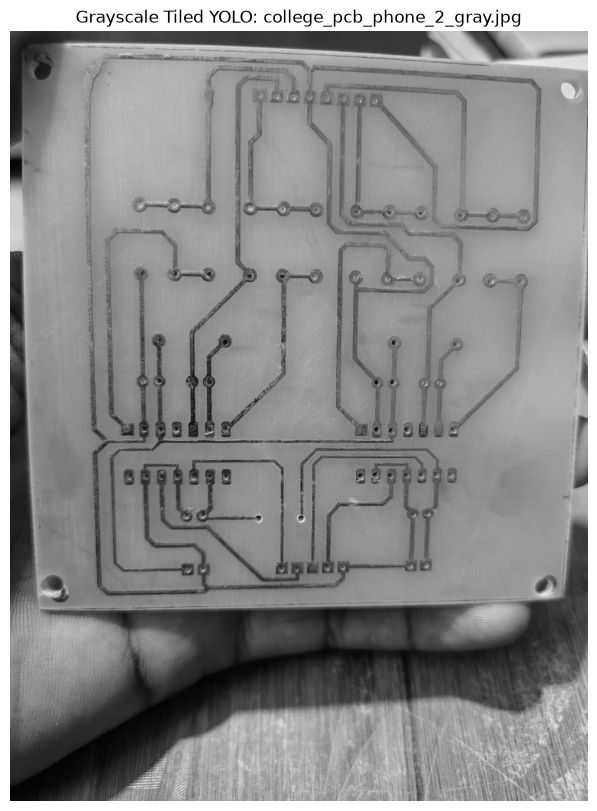

Final detections after NMS: 0
Saved result: D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_2_gray_tiled_predictions.jpg


In [18]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
from collections import defaultdict

# 1. Load trained model
model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

# 2. Grayscale images created in Step 1
image_paths = [
    Path(r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2_gray.jpg"),
    Path(r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_2_gray.jpg")
]

# 3. Inference settings
ROWS = 4
COLS = 3
CONFIDENCE = 0.25
IMGSZ = 608

for image_path in image_paths:

    print(f"\nProcessing: {image_path.name}")

    # Load grayscale image
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if gray is None:
        print(f"Image not found: {image_path}")
        continue

    # Convert to 3-channel grayscale so the model receives
    # a standard 3-channel image with grayscale appearance.
    image = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

    height, width = image.shape[:2]

    tile_width = width // COLS
    tile_height = height // ROWS

    all_boxes = []
    all_scores = []
    all_classes = []

    # 4. Run YOLO on each tile
    for row in range(ROWS):
        for col in range(COLS):

            x1 = col * tile_width
            y1 = row * tile_height

            x2 = width if col == COLS - 1 else (col + 1) * tile_width
            y2 = height if row == ROWS - 1 else (row + 1) * tile_height

            tile = image[y1:y2, x1:x2]

            results = model.predict(
                source=tile,
                imgsz=IMGSZ,
                conf=CONFIDENCE,
                device=0,
                verbose=False
            )

            # 5. Map tile coordinates back to full-image coordinates
            for result in results:
                if result.boxes is None:
                    continue

                for box in result.boxes:
                    bx1, by1, bx2, by2 = box.xyxy[0].cpu().numpy()

                    bx1 += x1
                    bx2 += x1
                    by1 += y1
                    by2 += y1

                    all_boxes.append([bx1, by1, bx2, by2])
                    all_scores.append(float(box.conf[0]))
                    all_classes.append(int(box.cls[0]))

    print("Raw tile detections:", len(all_boxes))

    # 6. Remove duplicate boxes using OpenCV NMS
    if all_boxes:
        boxes_for_nms = [
            [
                int(b[0]),
                int(b[1]),
                int(b[2] - b[0]),
                int(b[3] - b[1])
            ]
            for b in all_boxes
        ]

        indices = cv2.dnn.NMSBoxes(
            boxes_for_nms,
            all_scores,
            score_threshold=CONFIDENCE,
            nms_threshold=0.45
        )

        if len(indices) > 0:
            indices = indices.flatten().tolist()
        else:
            indices = []
    else:
        indices = []

    # 7. Draw combined detections on the full image
    output = image.copy()

    for idx in indices:
        x1, y1, x2, y2 = map(int, all_boxes[idx])
        class_id = all_classes[idx]
        score = all_scores[idx]
        class_name = model.names[class_id]

        cv2.rectangle(
            output, (x1, y1), (x2, y2),
            (255, 255, 255), 2
        )

        label = f"{class_name} {score:.2f}"

        cv2.putText(
            output, label,
            (x1, max(y1 - 6, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45, (255, 255, 255), 1,
            cv2.LINE_AA
        )

    # 8. Display and save results
    output_rgb = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 10))
    plt.imshow(output_rgb)
    plt.title(f"Grayscale Tiled YOLO: {image_path.name}")
    plt.axis("off")
    plt.show()

    save_path = image_path.with_name(
        image_path.stem + "_tiled_predictions.jpg"
    )

    cv2.imwrite(str(save_path), output)

    print("Final detections after NMS:", len(indices))
    print("Saved result:", save_path)


In [19]:

import cv2
from pathlib import Path
from ultralytics import YOLO

model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

image_paths = [
    Path(r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2_gray.jpg"),
    Path(r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_2_gray.jpg")
]

for path in image_paths:
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    print(f"\nImage: {path.name}")

    if image is None:
        print("ERROR: Image could not be loaded. Check the path.")
        continue

    print("Dimensions:", image.shape)
    print("Pixel range:", image.min(), "to", image.max())

    # YOLO receives a three-channel image with grayscale appearance
    image_3ch = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    for conf in [0.25, 0.10, 0.01]:
        results = model.predict(
            source=image_3ch,
            imgsz=608,
            conf=conf,
            device=0,
            verbose=False
        )

        boxes = results[0].boxes
        print(f"Confidence {conf:.2f}: {len(boxes)} detections")

        for box in boxes:
            class_id = int(box.cls[0])
            score = float(box.conf[0])
            print(f"  {model.names[class_id]}: {score:.3f}")



Image: college_pcb_phone_light_2_gray.jpg
Dimensions: (1280, 960)
Pixel range: 0 to 255
Confidence 0.25: 3 detections
  missing_hole: 0.333
  missing_hole: 0.318
  missing_hole: 0.286
Confidence 0.10: 8 detections
  missing_hole: 0.333
  missing_hole: 0.318
  missing_hole: 0.286
  missing_hole: 0.245
  missing_hole: 0.228
  missing_hole: 0.218
  missing_hole: 0.151
  missing_hole: 0.108
Confidence 0.01: 17 detections
  missing_hole: 0.333
  missing_hole: 0.318
  missing_hole: 0.286
  missing_hole: 0.245
  missing_hole: 0.228
  missing_hole: 0.218
  missing_hole: 0.151
  missing_hole: 0.108
  open_circuit: 0.044
  missing_hole: 0.043
  missing_hole: 0.033
  mouse_bite: 0.023
  missing_hole: 0.015
  missing_hole: 0.014
  missing_hole: 0.013
  missing_hole: 0.013
  missing_hole: 0.012

Image: college_pcb_phone_2_gray.jpg
Dimensions: (1280, 960)
Pixel range: 0 to 254
Confidence 0.25: 0 detections
Confidence 0.10: 0 detections
Confidence 0.01: 4 detections
  missing_hole: 0.087
  missing_h


college_pcb_phone_light_2.jpg: green PCB mask found
Final detections: 42
Saved: D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2_rgb_masked_tiled.jpg


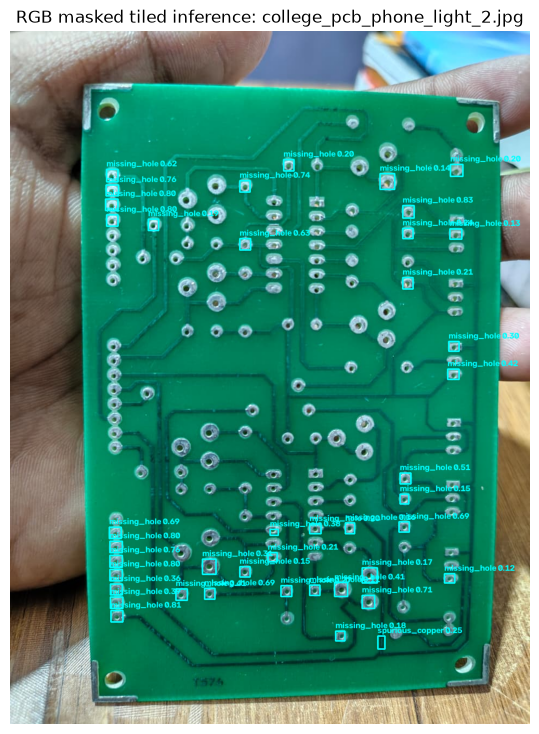


college_pcb_phone_2.jpg: green PCB mask found
Final detections: 3
Saved: D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_2_rgb_masked_tiled.jpg


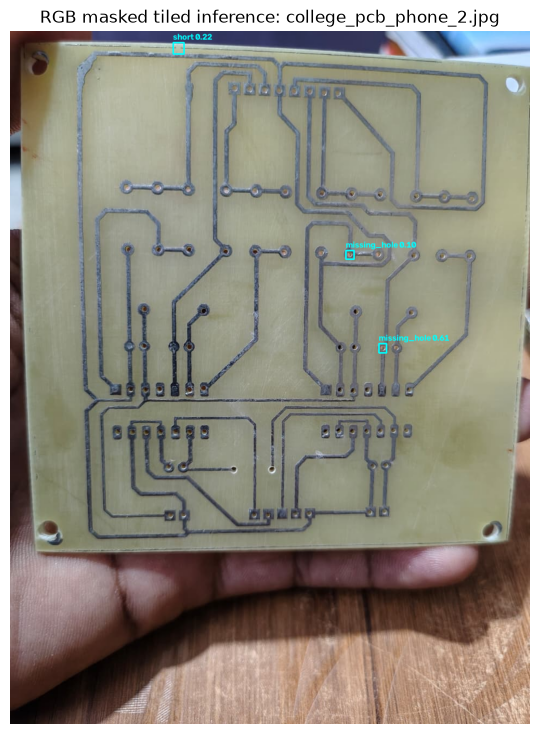

In [20]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

image_paths = [
    Path(r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2.jpg"),
    Path(r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_2.jpg")
]

TILE_W = 480
TILE_H = 360
OVERLAP = 0.20
CONF = 0.10

def make_starts(length, tile_size, overlap):
    if length <= tile_size:
        return [0]
    stride = max(1, int(tile_size * (1 - overlap)))
    starts = list(range(0, length - tile_size + 1, stride))
    if starts[-1] != length - tile_size:
        starts.append(length - tile_size)
    return sorted(set(starts))

for image_path in image_paths:
    image = cv2.imread(str(image_path))
    if image is None:
        print("Could not load:", image_path)
        continue

    # Find the board region in the original image.
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    green_mask = cv2.inRange(
        hsv, np.array([25, 30, 20]), np.array([100, 255, 255])
    )
    green_mask = cv2.morphologyEx(
        green_mask, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8),
        iterations=2
    )

    contours, _ = cv2.findContours(
        green_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    # For the beige PCB, green thresholding may fail.
    # Fall back to the whole image rather than silently using a bad mask.
    if contours and cv2.contourArea(max(contours, key=cv2.contourArea)) > 0.05 * image.shape[0] * image.shape[1]:
        contour = max(contours, key=cv2.contourArea)
        board_mask = np.zeros(image.shape[:2], dtype=np.uint8)
        cv2.drawContours(board_mask, [contour], -1, 255, thickness=cv2.FILLED)
        print(f"\n{image_path.name}: green PCB mask found")
    else:
        board_mask = np.full(image.shape[:2], 255, dtype=np.uint8)
        print(f"\n{image_path.name}: no green mask found; using full image")

    height, width = image.shape[:2]
    xs = make_starts(width, TILE_W, OVERLAP)
    ys = make_starts(height, TILE_H, OVERLAP)

    boxes, scores, classes = [], [], []

    for y in ys:
        for x in xs:
            tile = image[y:min(y + TILE_H, height),
                         x:min(x + TILE_W, width)]

            results = model.predict(
                source=tile, imgsz=608, conf=CONF,
                device=0, verbose=False
            )

            for box in results[0].boxes:
                bx1, by1, bx2, by2 = box.xyxy[0].cpu().numpy()
                cx = int(x + (bx1 + bx2) / 2)
                cy = int(y + (by1 + by2) / 2)

                # Reject detections whose center lies outside the board mask.
                if board_mask[cy, cx] == 0:
                    continue

                boxes.append([bx1 + x, by1 + y, bx2 + x, by2 + y])
                scores.append(float(box.conf[0]))
                classes.append(int(box.cls[0]))

    # Class-wise non-maximum suppression to merge duplicate tile detections.
    keep = []
    for class_id in set(classes):
        idxs = [i for i, c in enumerate(classes) if c == class_id]
        nms_boxes = [
            [int(boxes[i][0]), int(boxes[i][1]),
             int(boxes[i][2] - boxes[i][0]),
             int(boxes[i][3] - boxes[i][1])]
            for i in idxs
        ]
        nms_scores = [scores[i] for i in idxs]

        selected = cv2.dnn.NMSBoxes(
            nms_boxes, nms_scores, CONF, 0.45
        )
        if len(selected) > 0:
            keep.extend(idxs[int(k)] for k in np.array(selected).flatten())

    output = image.copy()
    for i in keep:
        x1, y1, x2, y2 = map(int, boxes[i])
        label = f"{model.names[classes[i]]} {scores[i]:.2f}"
        cv2.rectangle(output, (x1, y1), (x2, y2), (255, 255, 0), 2)
        cv2.putText(output, label, (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 2)

    save_path = image_path.with_name(image_path.stem + "_rgb_masked_tiled.jpg")
    cv2.imwrite(str(save_path), output)

    print("Final detections:", len(keep))
    print("Saved:", save_path)

    plt.figure(figsize=(9, 9))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title(f"RGB masked tiled inference: {image_path.name}")
    plt.axis("off")
    plt.show()


Confidence threshold 0.1: 23 detections


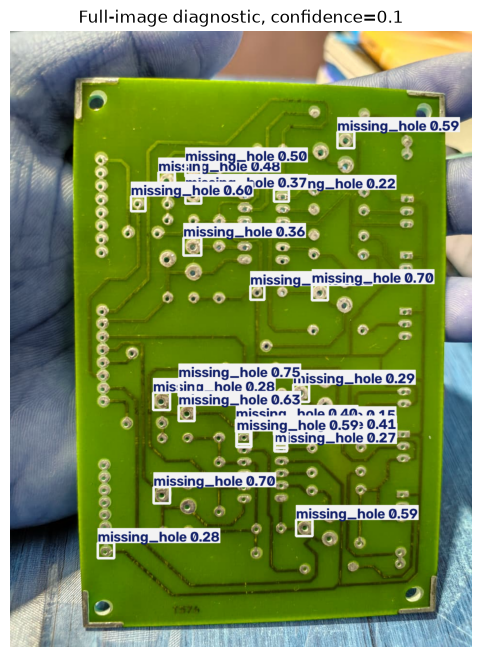

Confidence threshold 0.05: 31 detections


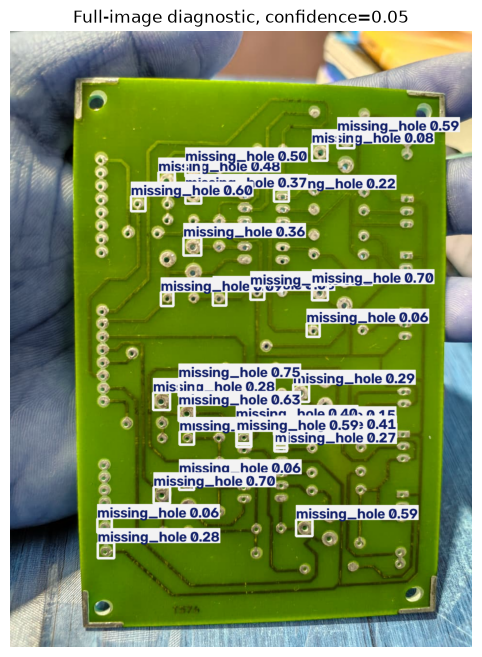

Confidence threshold 0.01: 59 detections


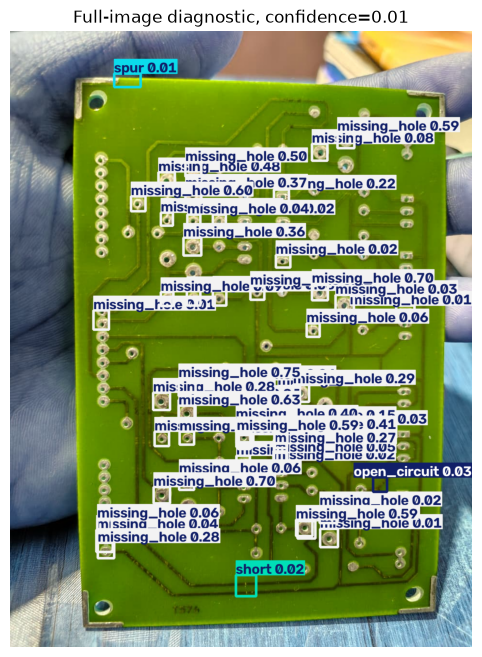

In [21]:
from pathlib import Path
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

model = YOLO(
    r"D:\PCB Defect Detection\results\pcb_yolo_baseline_w0\weights\best.pt"
)

image_path = Path(
    r"D:\PCB Defect Detection\pcb_test_images\college_pcb_phone_light_2.jpg"
)

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for conf in [0.10, 0.05, 0.01]:
    result = model.predict(
        source=image,
        imgsz=608,
        conf=conf,
        device=0,
        verbose=False
    )[0]

    output = result.plot()
    output = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)

    print(f"Confidence threshold {conf}: {len(result.boxes)} detections")

    plt.figure(figsize=(12, 8))
    plt.imshow(output)
    plt.title(f"Full-image diagnostic, confidence={conf}")
    plt.axis("off")
    plt.show()